# Assignment 2a: Color-Based Fruit Segmentation

This notebook reads the four supplied fruit images and saves masks and overlays under `output/part2a_segmentation/`.


In [4]:
%matplotlib inline

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np


## Part 2a: Color-Based Object Segmentation

The images are converted from BGR to HSV with cv2.cvtColor, then cv2.inRange creates binary masks. HSV separates hue from brightness, which helps distinguish fruit colors under uneven lighting. The red hue wraps around zero, so red ranges use two intervals.

In [5]:
import cv2

fruit_input_dir = Path('assignment-1-data')
fruit_output_dir = Path('output/part2a_segmentation')
fruit_output_dir.mkdir(parents=True, exist_ok=True)

# OpenCV HSV ranges use H in [0, 179] and S,V in [0, 255].
fruit_hsv_ranges = {
    'apples': [
        ((0, 55, 35), (12, 255, 255)),
        ((168, 55, 35), (179, 255, 255)),
    ],
    'apples2': [
        ((0, 50, 35), (15, 255, 255)),
        ((165, 50, 35), (179, 255, 255)),
        ((15, 45, 40), (40, 255, 255)),
        ((35, 45, 35), (90, 255, 255)),
    ],
    'blackberries': [
        ((0, 0, 0), (179, 255, 65)),
        ((105, 25, 20), (179, 255, 165)),
    ],
    'cherries': [
        ((0, 100, 35), (12, 255, 255)),
        ((168, 100, 35), (179, 255, 255)),
    ],
}

fruit_results = {}
for fruit_name, ranges in fruit_hsv_ranges.items():
    input_path = fruit_input_dir / f'{fruit_name}.jpg'
    bgr = cv2.imread(str(input_path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(f'Could not read {input_path}')
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    mask = np.zeros(hsv.shape[:2], dtype=np.uint8)
    for lower, upper in ranges:
        mask = cv2.bitwise_or(
            mask,
            cv2.inRange(hsv, np.array(lower, dtype=np.uint8), np.array(upper, dtype=np.uint8)),
        )

    # Tint detected pixels green so the segmentation can be inspected on the image.
    green = np.zeros_like(bgr)
    green[:, :, 1] = 255
    overlay = cv2.addWeighted(bgr, 0.6, green, 0.4, 0)
    overlay[mask == 0] = bgr[mask == 0]

    mask_path = fruit_output_dir / f'{fruit_name}_mask.png'
    overlay_path = fruit_output_dir / f'{fruit_name}_overlay.png'
    cv2.imwrite(str(mask_path), mask)
    cv2.imwrite(str(overlay_path), overlay)
    fruit_results[fruit_name] = {
        'bgr': bgr,
        'mask': mask,
        'overlay': overlay,
        'coverage_percent': 100 * np.count_nonzero(mask) / mask.size,
    }
    print(f'{fruit_name}: segmented {fruit_results[fruit_name]["coverage_percent"]:.1f}% of pixels')


apples: segmented 31.3% of pixels
apples2: segmented 88.8% of pixels
blackberries: segmented 32.1% of pixels
cherries: segmented 43.9% of pixels


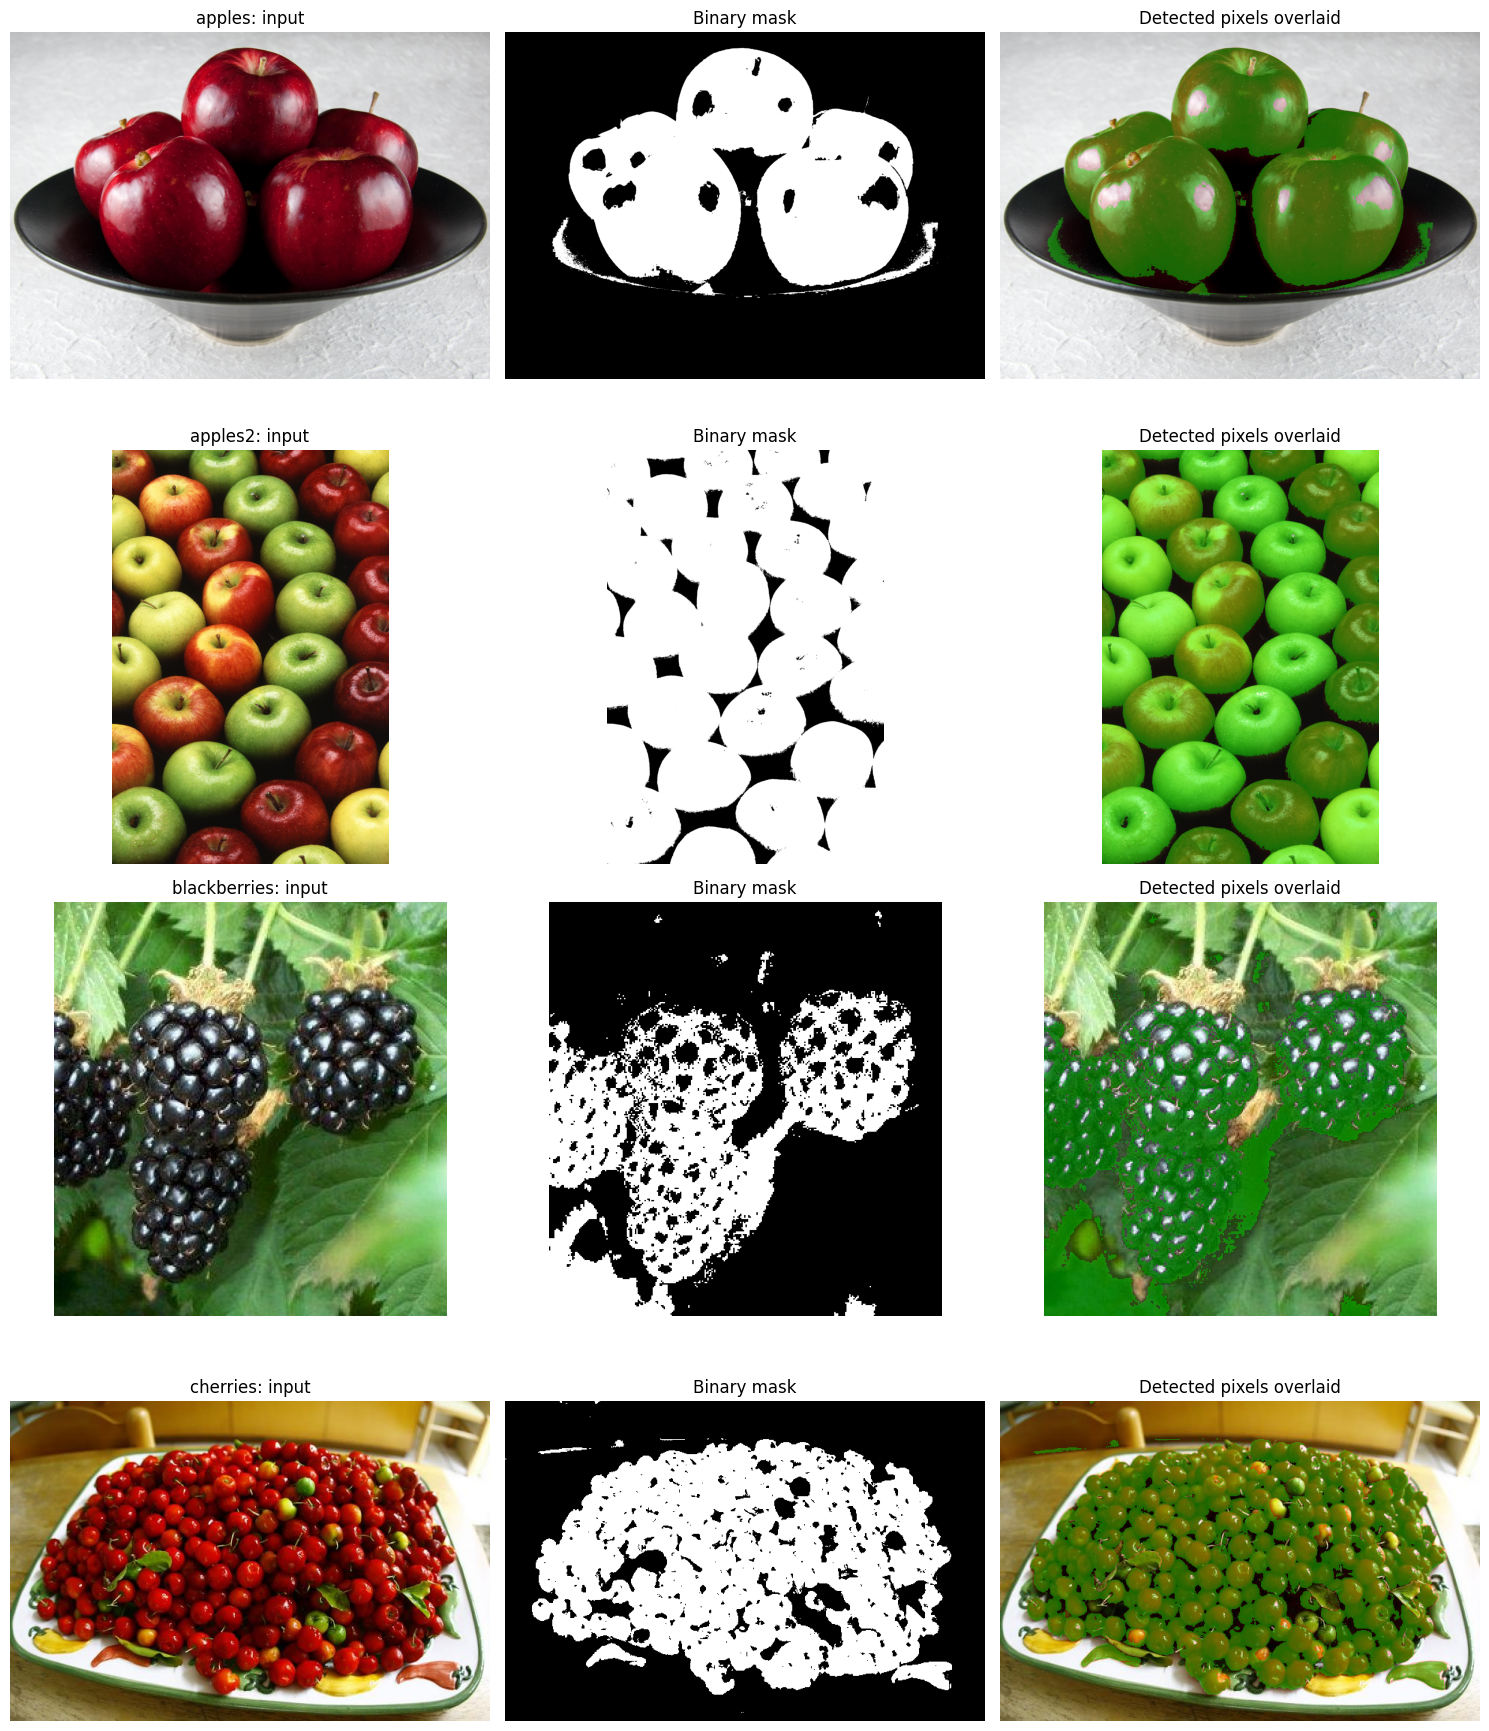

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(15, 18))
for row, fruit_name in enumerate(fruit_hsv_ranges):
    result = fruit_results[fruit_name]
    axes[row, 0].imshow(cv2.cvtColor(result['bgr'], cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f'{fruit_name}: input')
    axes[row, 1].imshow(result['mask'], cmap='gray', vmin=0, vmax=255)
    axes[row, 1].set_title('Binary mask')
    axes[row, 2].imshow(cv2.cvtColor(result['overlay'], cv2.COLOR_BGR2RGB))
    axes[row, 2].set_title('Detected pixels overlaid')
    for axis in axes[row]:
        axis.axis('off')
plt.tight_layout()
plt.show()


### Part 2a threshold choices and observations

| Image | HSV ranges (OpenCV hue 0-179) | Reason and result |
|---|---|---|
| apples.jpg | H 0-12 or 168-179; S at least 55; V at least 35 | Select saturated red apple skin while rejecting most pale backdrop and dark bowl pixels. |
| apples2.jpg | Red: H 0-15 or 165-179, S at least 50, V at least 35; yellow/orange: H 15-40, S at least 45, V at least 40; green: H 35-90, S at least 45, V at least 35 | Include red, yellow/orange, and green apples against a dark background. |
| blackberries.jpg | Any hue with V at most 65, or H 105-179, S at least 25, V 20-165 | Capture near-black berry pixels and brighter purple highlights. |
| cherries.jpg | H 0-12 or 168-179; S at least 100; V at least 35 | Isolate saturated red cherries against the pale plate and foliage. |

The ranges were selected by visually checking each supplied image and adjusting them to retain fruit pixels while rejecting as much background as possible; the overlays show the resulting trade-offs. The masks retain the main fruit areas. The apple mask selects visible segments along the bowl rim while rejecting most of the bowl interior, and misses glossy white highlights. The mixed-apple mask captures fruit of several colors but leaves small dark gaps around some stems and misses a few bright highlights. The blackberry mask captures the dark clusters, but its all-hue low-value range also selects some dark leaves and shadows. The cherry mask detects red cherries but misses green/yellow cherries whose colors overlap foliage; relaxing the saturation threshold would increase leaf false positives. Pixel coverage is printed above for each image. These examples show the limits of color-only thresholding.
